# OLA Ride Insights — Data Cleaning & EDA
**Dataset:** 103,024 OLA bookings, Bengaluru, July 2024 (`OLA_DataSet.xlsx`, sheet *July*).

Steps: 1) understand the data → 2) clean & engineer features (`data_prep.py`) → 3) EDA → 4) SQL answers → 5) export for Power BI / Streamlit.

In [1]:
import sys, sqlite3
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from data_prep import clean, to_sqlite, CLEAN_CSV
from queries import QUERIES

sns.set_theme(style="whitegrid", palette="Greens_r")
pd.set_option("display.max_columns", 50)

## 1. Data understanding

In [2]:
raw = pd.read_excel(ROOT / "data" / "OLA_DataSet.xlsx", sheet_name="July")
print(raw.shape)
raw.head()

(103024, 20)


,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Date                        103024 non-null  datetime64[us]
 1   Time                        103024 non-null  object        
 2   Booking_ID                  103024 non-null  str           
 3   Booking_Status              103024 non-null  str           
 4   Customer_ID                 103024 non-null  str           
 5   Vehicle_Type                103024 non-null  str           
 6   Pickup_Location             103024 non-null  str           
 7   Drop_Location               103024 non-null  str           
 8   V_TAT                       63967 non-null   float64       
 9   C_TAT                       63967 non-null   float64       
 10  Canceled_Rides_by_Customer  10499 non-null   str           
 11  Canceled_Rides_by_Driver    18434 non-null   str  

In [4]:
miss = raw.isna().sum().to_frame("missing")
miss["pct"] = (miss["missing"] / len(raw) * 100).round(1)
miss[miss.missing > 0]

,missing,pct
V_TAT,39057,37.9
C_TAT,39057,37.9
Canceled_Rides_by_Customer,92525,89.8
Canceled_Rides_by_Driver,84590,82.1
Incomplete_Rides,39057,37.9
Incomplete_Rides_Reason,99098,96.2
Payment_Method,39057,37.9
Driver_Ratings,39057,37.9
Customer_Rating,39057,37.9


**Observation:** the 39,057 nulls in `V_TAT, C_TAT, Payment_Method, Driver_Ratings, Customer_Rating, Incomplete_Rides` are exactly the non-successful bookings — they are *structurally* missing (a cancelled ride has no payment or rating), so they are kept as NULL rather than imputed.

In [5]:
pd.crosstab(raw["Booking_Status"], raw["Payment_Method"].isna(), margins=True)

Payment_Method,False,True,All
Booking_Status,,,
Canceled by Customer,0,10499,10499
Canceled by Driver,0,18434,18434
Driver Not Found,0,10124,10124
Success,63967,0,63967
All,63967,39057,103024


In [6]:
for c in ["Booking_Status", "Vehicle_Type", "Payment_Method",
          "Canceled_Rides_by_Customer", "Canceled_Rides_by_Driver", "Incomplete_Rides_Reason"]:
    print(f"\n--- {c}"); print(raw[c].value_counts(dropna=False))


--- Booking_Status
Booking_Status
Success                 63967
Canceled by Driver      18434
Canceled by Customer    10499
Driver Not Found        10124
Name: count, dtype: int64

--- Vehicle_Type
Vehicle_Type
Prime Sedan    14877
eBike          14816
Auto           14755
Prime Plus     14707
Bike           14662
Prime SUV      14655
Mini           14552
Name: count, dtype: int64

--- Payment_Method
Payment_Method
NaN            39057
Cash           35022
UPI            25881
Credit Card     2435
Debit Card       629
Name: count, dtype: int64

--- Canceled_Rides_by_Customer
Canceled_Rides_by_Customer
NaN                                             92525
Driver is not moving towards pickup location     3175
Driver asked to cancel                           2670
Change of plans                                  2081
AC is Not working                                1568
Wrong Address                                    1005
Name: count, dtype: int64

--- Canceled_Rides_by_Driver
Canceled_R

## 2. Cleaning & feature engineering
`clean()` in `data_prep.py`: trims text, removes duplicates, parses datetime, validates ratings (1–5), blanks payment for non-successful rides, and adds `Ride_Hour, Day_Name, Time_Slot, Is_Weekend, Cancelled_By, Cancellation_Reason, Revenue, Fare_per_KM, Distance_Band, Route, Is_Fare_Anomaly`.

In [7]:
df = clean(raw)
print(df.shape, "| duplicates removed:", len(raw) - len(df))
df.head()

(103024, 37) | duplicates removed: 0


,Booking_ID,Booking_DateTime,Ride_Date,Ride_Time,Ride_Hour,Day_of_Month,Day_Name,Week_No,Is_Weekend,Time_Slot,Booking_Status,Is_Success,Is_Completed,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,Route,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Cancelled_By,Cancellation_Reason,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Revenue,Payment_Method,Ride_Distance,Distance_Band,Fare_per_KM,Driver_Ratings,Customer_Rating,Is_Fare_Anomaly,Is_Same_Pickup_Drop,Vehicle_Image_URL
0,CNR4197668379,2024-07-01 00:00:00,2024-07-01,00:00:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID451984,Prime Plus,Malleshwaram,BTM Layout,Malleshwaram -> BTM Layout,238.0,140.0,<NA>,<NA>,Not Cancelled,<NA>,No,<NA>,791,791,Cash,31,31-50 km,25.52,3.1,4.7,0,0,https://cdn-icons-png.flaticon.com/128/11409/1...
1,CNR4091573505,2024-07-01 00:00:00,2024-07-01,00:00:00,0,1,Monday,27,0,Night (21-5),Canceled by Driver,0,0,CID742344,eBike,Yeshwanthpur,Devanahalli,Yeshwanthpur -> Devanahalli,NaN,NaN,<NA>,Customer was coughing/sick,Driver,Customer was coughing/sick,Not Applicable,<NA>,367,0,<NA>,0,0 km (no ride),NaN,NaN,NaN,0,0,https://cdn-icons-png.flaticon.com/128/6839/68...
2,CNR7037451850,2024-07-01 00:02:00,2024-07-01,00:02:00,0,1,Monday,27,0,Night (21-5),Canceled by Driver,0,0,CID159762,Mini,Padmanabhanagar,Magadi Road,Padmanabhanagar -> Magadi Road,NaN,NaN,<NA>,More than permitted people in there,Driver,More than permitted people in there,Not Applicable,<NA>,1985,0,<NA>,0,0 km (no ride),NaN,NaN,NaN,0,0,https://cdn-icons-png.flaticon.com/128/3202/32...
3,CNR3610392570,2024-07-01 00:03:00,2024-07-01,00:03:00,0,1,Monday,27,0,Night (21-5),Success,1,0,CID569014,eBike,JP Nagar,Sarjapur Road,JP Nagar -> Sarjapur Road,196.0,60.0,<NA>,<NA>,Not Cancelled,<NA>,Yes,Customer Demand,120,120,Credit Card,26,16-30 km,4.62,3.1,4.4,0,0,https://cdn-icons-png.flaticon.com/128/6839/68...
4,CNR8282131599,2024-07-01 00:04:00,2024-07-01,00:04:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID332553,Auto,Langford Town,JP Nagar,Langford Town -> JP Nagar,259.0,140.0,<NA>,<NA>,Not Cancelled,<NA>,No,<NA>,170,170,Cash,5,1-5 km,34.00,4.3,3.5,0,0,https://cdn-icons-png.flaticon.com/128/16526/1...


In [8]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Booking_DateTime,103024,2024-07-16 11:31:38.879678,2024-07-01 00:00:00,2024-07-08 18:41:00,2024-07-16 11:23:00,2024-07-24 05:18:00,2024-07-31 23:58:00,NaN
Ride_Hour,103024.0,11.485528,0.0,6.0,11.0,17.0,23.0,6.912131
Day_of_Month,103024.0,15.981267,1.0,8.0,16.0,24.0,31.0,8.931225
Week_No,103024.0,28.741293,27.0,28.0,29.0,30.0,31.0,1.29232
Is_Weekend,103024.0,0.255804,0.0,0.0,0.0,1.0,1.0,0.436315
Is_Success,103024.0,0.620894,0.0,0.0,1.0,1.0,1.0,0.485167
Is_Completed,103024.0,0.582787,0.0,0.0,1.0,1.0,1.0,0.493101
V_TAT,63967.0,170.876952,35.0,98.0,168.0,238.0,308.0,80.80364
C_TAT,63967.0,84.873372,25.0,55.0,85.0,115.0,145.0,36.0051
Booking_Value,103024.0,548.751883,100.0,242.0,386.0,621.0,2999.0,536.541221


## 3. Exploratory data analysis

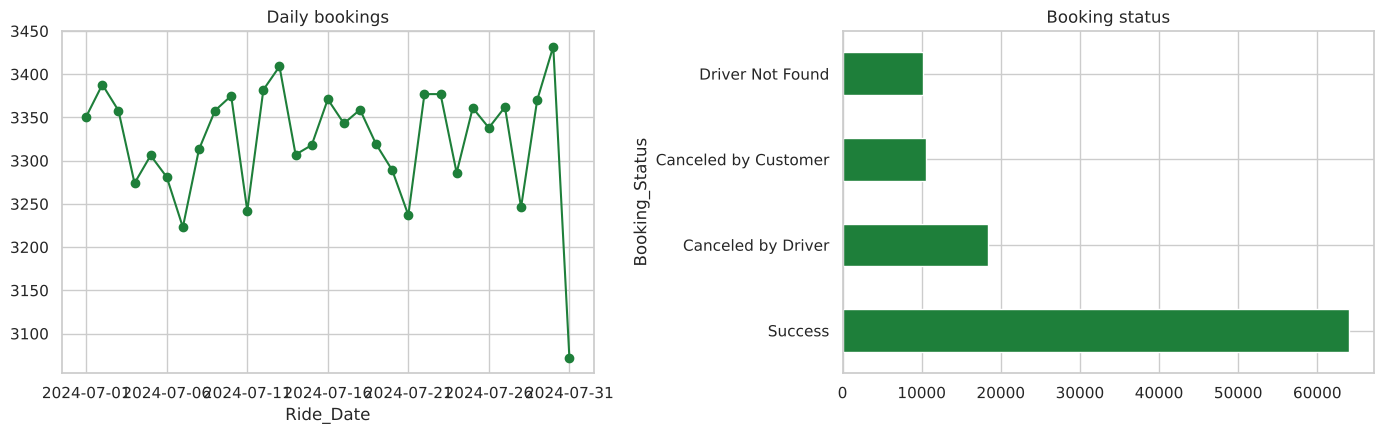

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
df.groupby("Ride_Date").size().plot(ax=ax[0], marker="o", color="#1E7F3A", title="Daily bookings")
df["Booking_Status"].value_counts().plot.barh(ax=ax[1], color="#1E7F3A", title="Booking status")
plt.tight_layout()

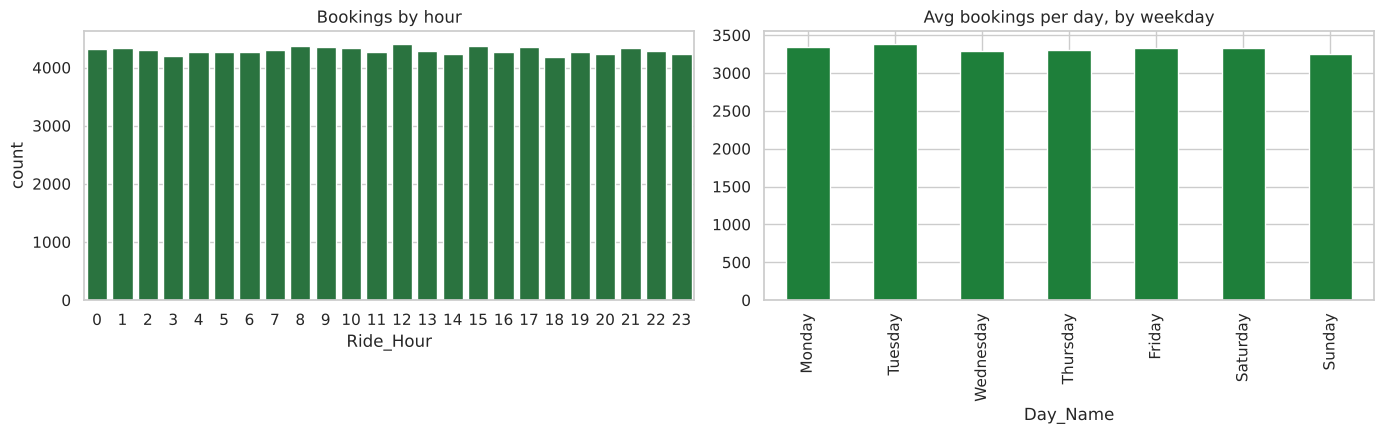

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=df, x="Ride_Hour", color="#1E7F3A", ax=ax[0]).set_title("Bookings by hour")
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
per_day = df.groupby(["Ride_Date","Day_Name"]).size().groupby("Day_Name").mean().reindex(order)
per_day.plot.bar(ax=ax[1], color="#1E7F3A", title="Avg bookings per day, by weekday")
plt.tight_layout()

Raw weekday totals look higher for Mon–Wed only because July 2024 has five of each; per-day averages are flat.

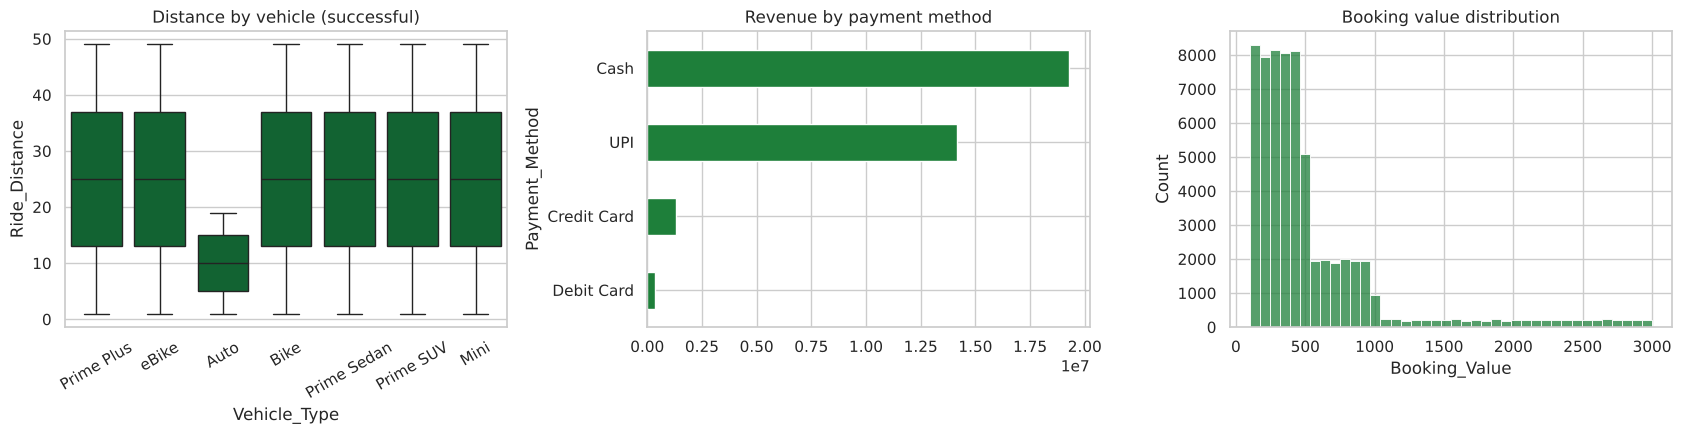

In [11]:
succ = df[df.Booking_Status == "Success"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=succ, x="Vehicle_Type", y="Ride_Distance", ax=ax[0]).set_title("Distance by vehicle (successful)")
succ.groupby("Payment_Method")["Booking_Value"].sum().sort_values().plot.barh(ax=ax[1], color="#1E7F3A", title="Revenue by payment method")
sns.histplot(succ["Booking_Value"], bins=40, ax=ax[2], color="#1E7F3A").set_title("Booking value distribution")
for a in ax[:1]: a.tick_params(axis="x", rotation=30)
plt.tight_layout()

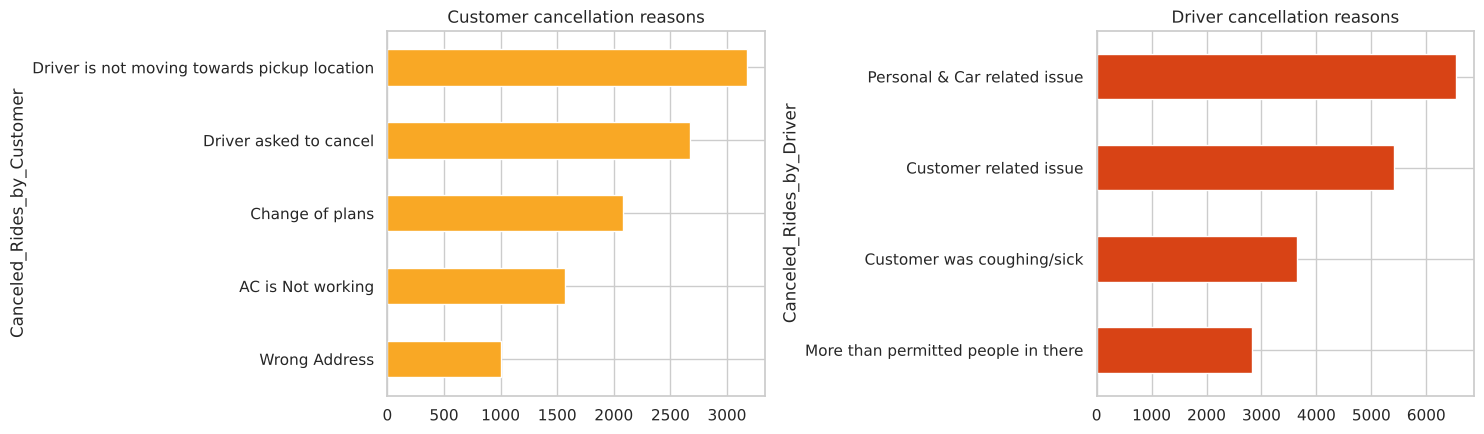

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
df["Canceled_Rides_by_Customer"].value_counts().sort_values().plot.barh(ax=ax[0], color="#F9A825", title="Customer cancellation reasons")
df["Canceled_Rides_by_Driver"].value_counts().sort_values().plot.barh(ax=ax[1], color="#D84315", title="Driver cancellation reasons")
plt.tight_layout()

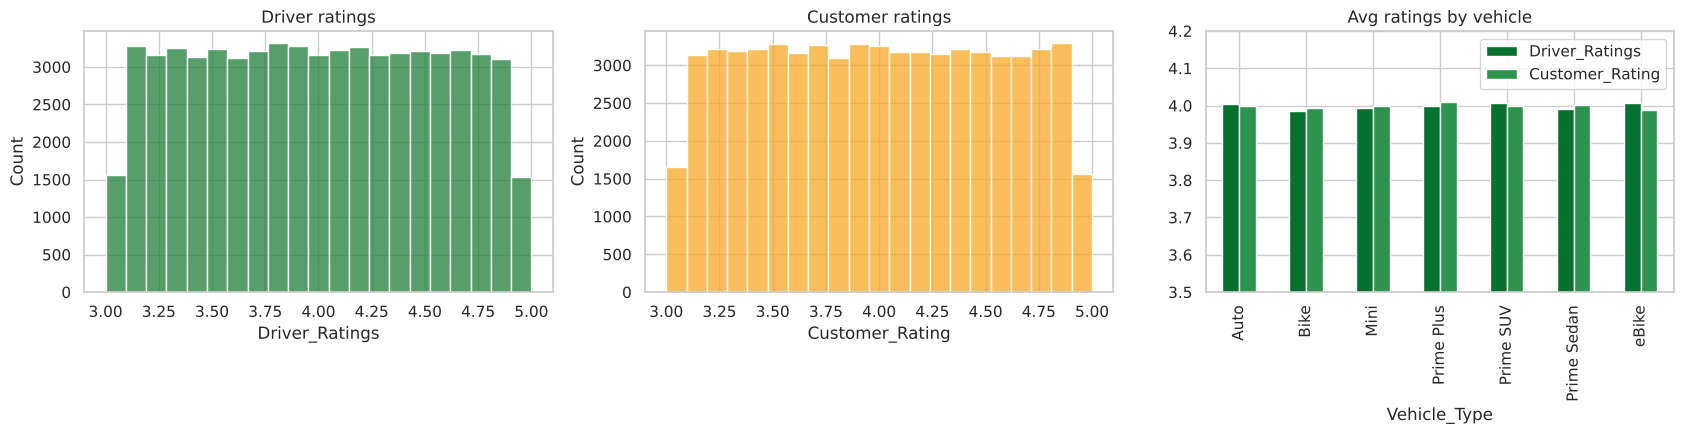

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(succ["Driver_Ratings"], bins=21, ax=ax[0], color="#1E7F3A").set_title("Driver ratings")
sns.histplot(succ["Customer_Rating"], bins=21, ax=ax[1], color="#F9A825").set_title("Customer ratings")
succ.groupby("Vehicle_Type")[["Driver_Ratings","Customer_Rating"]].mean().plot.bar(ax=ax[2], ylim=(3.5,4.2), title="Avg ratings by vehicle")
plt.tight_layout()

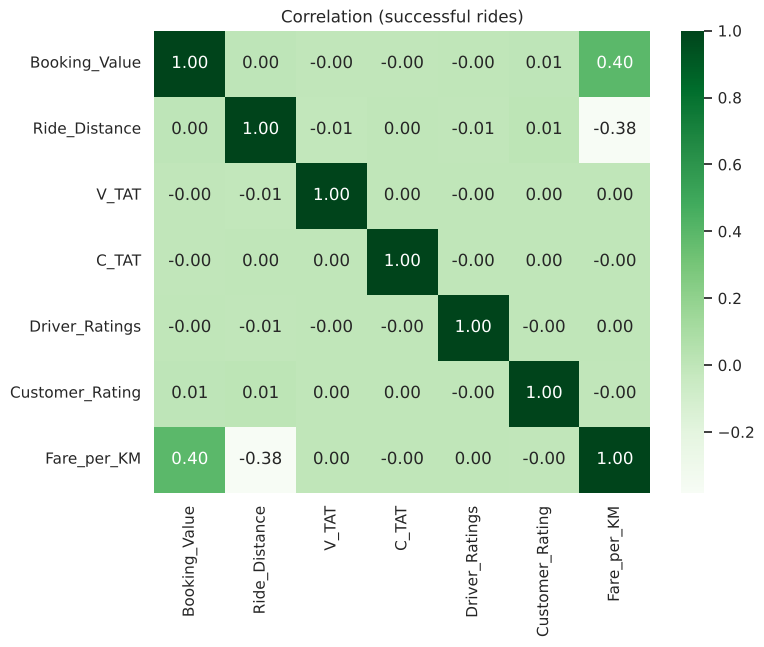

In [14]:
num = succ[["Booking_Value","Ride_Distance","V_TAT","C_TAT","Driver_Ratings","Customer_Rating","Fare_per_KM"]]
plt.figure(figsize=(8,6)); sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="Greens"); plt.title("Correlation (successful rides)");

### Anomaly detection — fare per km (IQR, k = 3)

In [15]:
print("Flagged rides:", df.Is_Fare_Anomaly.sum(), f"({df.Is_Fare_Anomaly.sum()/len(succ):.1%} of successful)")
df[df.Is_Fare_Anomaly == 1].sort_values("Fare_per_KM", ascending=False)[
    ["Booking_ID","Vehicle_Type","Route","Ride_Distance","Booking_Value","Fare_per_KM"]].head(10)

Flagged rides: 4460 (7.0% of successful)


,Booking_ID,Vehicle_Type,Route,Ride_Distance,Booking_Value,Fare_per_KM
92639,CNR9360526727,eBike,Cox Town -> Rajajinagar,1,2981,2981.0
74296,CNR7114242598,Auto,Devanahalli -> Majestic,1,2940,2940.0
47770,CNR3047071055,Prime Plus,MG Road -> Mysore Road,1,2932,2932.0
82666,CNR6466436239,Auto,Richmond Town -> Electronic City,1,2928,2928.0
99745,CNR9021264849,eBike,Magadi Road -> Magadi Road,1,2920,2920.0
68413,CNR9790418029,Mini,Nagarbhavi -> Frazer Town,1,2909,2909.0
23213,CNR8409773258,Bike,Vijayanagar -> Chamarajpet,1,2855,2855.0
97539,CNR1347216999,Mini,Ulsoor -> Bellandur,1,2839,2839.0
31249,CNR1436222892,Auto,Shantinagar -> Yeshwanthpur,1,2801,2801.0
72661,CNR3400600266,Prime Plus,Chamarajpet -> Shantinagar,1,2769,2769.0


## 4. SQL answers (SQLite — same SQL as `sql/ola_queries.sql`)

In [16]:
df.to_csv(CLEAN_CSV, index=False, compression="gzip")
to_sqlite(df)
con = sqlite3.connect(ROOT / "data" / "ola.db")
for title, q in QUERIES.items():
    res = pd.read_sql(q["sql"], con)
    print(f"\n{title}  ->  {len(res):,} rows")
    display(res.head(10))


Q1. Retrieve all successful bookings  ->  63,967 rows


,Booking_ID,Booking_DateTime,Ride_Date,Ride_Time,Ride_Hour,Day_of_Month,Day_Name,Week_No,Is_Weekend,Time_Slot,Booking_Status,Is_Success,Is_Completed,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,Route,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Cancelled_By,Cancellation_Reason,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Revenue,Payment_Method,Ride_Distance,Distance_Band,Fare_per_KM,Driver_Ratings,Customer_Rating,Is_Fare_Anomaly,Is_Same_Pickup_Drop,Vehicle_Image_URL
0,CNR4197668379,2024-07-01 00:00:00,2024-07-01,00:00:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID451984,Prime Plus,Malleshwaram,BTM Layout,Malleshwaram -> BTM Layout,238.0,140.0,None,None,Not Cancelled,None,No,NaN,791,791,Cash,31,31-50 km,25.52,3.1,4.7,0,0,https://cdn-icons-png.flaticon.com/128/11409/1...
1,CNR3610392570,2024-07-01 00:03:00,2024-07-01,00:03:00,0,1,Monday,27,0,Night (21-5),Success,1,0,CID569014,eBike,JP Nagar,Sarjapur Road,JP Nagar -> Sarjapur Road,196.0,60.0,None,None,Not Cancelled,None,Yes,Customer Demand,120,120,Credit Card,26,16-30 km,4.62,3.1,4.4,0,0,https://cdn-icons-png.flaticon.com/128/6839/68...
2,CNR8282131599,2024-07-01 00:04:00,2024-07-01,00:04:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID332553,Auto,Langford Town,JP Nagar,Langford Town -> JP Nagar,259.0,140.0,None,None,Not Cancelled,None,No,NaN,170,170,Cash,5,1-5 km,34.00,4.3,3.5,0,0,https://cdn-icons-png.flaticon.com/128/16526/1...
3,CNR8299032288,2024-07-01 00:04:00,2024-07-01,00:04:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID874321,Bike,Shivajinagar,Ulsoor,Shivajinagar -> Ulsoor,105.0,115.0,None,None,Not Cancelled,None,No,NaN,239,239,Cash,14,6-15 km,17.07,5.0,3.5,0,0,https://cdn-icons-png.flaticon.com/128/9983/99...
4,CNR4163786807,2024-07-01 00:04:00,2024-07-01,00:04:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID967658,Prime Sedan,Hebbal,Varthur,Hebbal -> Varthur,280.0,130.0,None,None,Not Cancelled,None,No,NaN,914,914,UPI,3,1-5 km,304.67,4.8,3.3,1,0,https://cdn-icons-png.flaticon.com/128/14183/1...
5,CNR4467034507,2024-07-01 00:04:00,2024-07-01,00:04:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID783274,Prime Plus,Cox Town,Yelahanka,Cox Town -> Yelahanka,224.0,125.0,None,None,Not Cancelled,None,No,NaN,432,432,Cash,26,16-30 km,16.62,3.8,3.5,0,0,https://cdn-icons-png.flaticon.com/128/11409/1...
6,CNR2979520888,2024-07-01 00:05:00,2024-07-01,00:05:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID815153,eBike,Indiranagar,JP Nagar,Indiranagar -> JP Nagar,224.0,60.0,None,None,Not Cancelled,None,No,NaN,127,127,Cash,10,6-15 km,12.70,3.9,4.1,0,0,https://cdn-icons-png.flaticon.com/128/6839/68...
7,CNR5741290724,2024-07-01 00:05:00,2024-07-01,00:05:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID433994,Bike,Devanahalli,Chickpet,Devanahalli -> Chickpet,280.0,75.0,None,None,Not Cancelled,None,No,NaN,359,359,UPI,42,31-50 km,8.55,4.5,4.9,0,0,https://cdn-icons-png.flaticon.com/128/9983/99...
8,CNR6847847892,2024-07-01 00:05:00,2024-07-01,00:05:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID687346,Prime Sedan,Cox Town,MG Road,Cox Town -> MG Road,210.0,95.0,None,None,Not Cancelled,None,No,NaN,943,943,Cash,22,16-30 km,42.86,4.2,4.8,0,0,https://cdn-icons-png.flaticon.com/128/14183/1...
9,CNR7758635148,2024-07-01 00:06:00,2024-07-01,00:06:00,0,1,Monday,27,0,Night (21-5),Success,1,1,CID459435,Prime Sedan,Hulimavu,Padmanabhanagar,Hulimavu -> Padmanabhanagar,182.0,125.0,None,None,Not Cancelled,None,No,NaN,881,881,Cash,27,16-30 km,32.63,3.3,4.6,0,0,https://cdn-icons-png.flaticon.com/128/14183/1...



Q2. Average ride distance for each vehicle type  ->  7 rows


,Vehicle_Type,Avg_Distance_All_Bookings,Avg_Distance_Successful
0,Prime Sedan,15.76,25.01
1,eBike,15.58,25.15
2,Bike,15.53,24.93
3,Mini,15.51,24.98
4,Prime Plus,15.45,25.03
5,Prime SUV,15.27,24.88
6,Auto,6.24,10.04



Q3. Total number of rides cancelled by customers  ->  1 rows


,Total_Cancelled_By_Customers
0,10499


... (10 outputs left out)


Q9. Total booking value of successfully completed rides  ->  1 rows


,Total_Successful_Booking_Value,Value_Fully_Completed_Rides
0,35080467,32829985



Q10. All incomplete rides with reason  ->  3,926 rows


,Booking_ID,Ride_Date,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,Incomplete_Rides_Reason
0,CNR3610392570,2024-07-01,CID569014,eBike,JP Nagar,Sarjapur Road,Customer Demand
1,CNR3318158193,2024-07-01,CID567241,Prime Plus,Koramangala,Kengeri,Other Issue
2,CNR2686959624,2024-07-01,CID250621,eBike,Shivajinagar,Chamarajpet,Customer Demand
3,CNR7652372986,2024-07-01,CID458607,Bike,Electronic City,Jayanagar,Other Issue
4,CNR3946841728,2024-07-01,CID979652,Mini,Koramangala,HSR Layout,Vehicle Breakdown
5,CNR6620843617,2024-07-01,CID485768,Bike,Vijayanagar,Peenya,Vehicle Breakdown
6,CNR2938090917,2024-07-01,CID873875,Prime SUV,Rajajinagar,Bannerghatta Road,Customer Demand
7,CNR1577787158,2024-07-01,CID815622,Auto,Yeshwanthpur,Peenya,Customer Demand
8,CNR3356976817,2024-07-01,CID469728,Prime SUV,Indiranagar,Majestic,Other Issue
9,CNR5658866654,2024-07-01,CID646144,Mini,Koramangala,HSR Layout,Vehicle Breakdown


## 5. Key insights
1. **62% success rate** — 38% of bookings (≈₹2.15 Cr booking value) never become rides.
2. **Drivers cancel 1.8× more than customers** (17.9% vs 10.2%); top driver reason is *Personal & Car related issue*, top customer reason is *Driver not moving towards pickup*.
3. **Cash is still 55% of revenue**, UPI 40%; cards are under 5%.
4. **Demand is flat** across hours and weekdays (~3,300 bookings/day) — supply planning should be even, not peak-only.
5. **Auto** trips are short (~10 km avg); all other categories average ~25 km.
6. Ratings cluster around 4.0 for all vehicle types; there is no weak category.
7. ~7% of successful rides have extreme fare/km — worth an audit for fraud or pricing errors.